# 05.8 · Explaining models: feature importance, permutation importance, SHAP

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/05-powerful-models/08-explaining-models/lesson.ipynb)

Read the [README](README.md) and do the two hand calculations (permutation drop and the two-feature Shapley split). This notebook:

1. Loads the tuned churn model from 05.6.
2. Shows why the built-in feature importance can mislead, and computes permutation importance.
3. Draws partial dependence: how predicted churn changes as one feature changes.
4. Checks the Shapley split by hand, then explains the whole model and one customer with SHAP.

## 1. The model to explain

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail
from sklearn.model_selection import train_test_split

raw = load_retail("Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

cutoff = pd.Timestamp("2011-09-01")                       # features before, target after
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]

cust = past.groupby("Customer ID").agg(orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
                                       products=("StockCode", "nunique"),
                                       first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"))
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
future_spend = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust["churned"] = (future_spend == 0).astype(int)        # 1 = did not come back
cust = cust.drop(columns=["first_order", "last_order"])

features = ["orders", "spend", "products", "tenure_days", "days_since_last"]
X_train, X_test, y_train, y_test = train_test_split(
    cust[features], cust["churned"], test_size=0.25, random_state=42, stratify=cust["churned"])
print(f"{len(cust):,} customers, churn rate {cust['churned'].mean():.1%}, "
      f"train {len(X_train):,} / test {len(X_test):,}")

import lightgbm as lgb
from sklearn.metrics import roc_auc_score
# the tuned settings found by grid search in 05.6
model = lgb.LGBMClassifier(n_estimators=200, learning_rate=0.01, num_leaves=4,
                           verbose=-1, random_state=42, n_jobs=1).fit(X_train, y_train)
print(f"tuned LightGBM, test AUC {roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]):.3f}")

3,317 customers, churn rate 43.6%, train 2,487 / test 830
tuned LightGBM, test AUC 0.739


## 2. Built-in importance and its trap

Tree models count how much each feature was used to reduce impurity. It is fast, but it favours features with **many distinct values**, because they offer more possible split points, even when those splits are noise.

To see the trap, add a column of pure random numbers and fit a deep random forest.

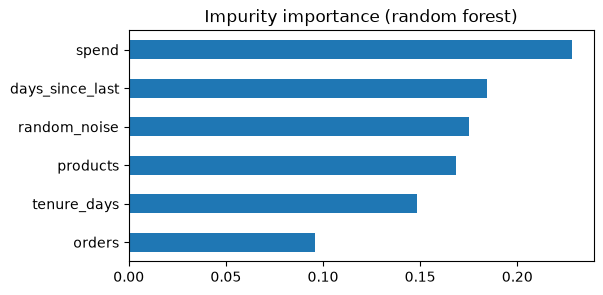

orders             0.096
tenure_days        0.148
products           0.168
random_noise       0.175
days_since_last    0.184
spend              0.228
dtype: float64

In [2]:
from sklearn.ensemble import RandomForestClassifier
rng = np.random.default_rng(0)
X_tr_noise = X_train.assign(random_noise=rng.normal(size=len(X_train)))
X_te_noise = X_test.assign(random_noise=rng.normal(size=len(X_test)))
rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1).fit(X_tr_noise, y_train)

impurity = pd.Series(rf.feature_importances_, index=X_tr_noise.columns).sort_values()
impurity.plot.barh(figsize=(6, 3), title="Impurity importance (random forest)")
plt.show(); impurity.round(3)

The random column gets a sizeable share of importance despite carrying no information at all. The forest used it to memorise individual training customers.

## 3. Permutation importance: by hand, then for real

The idea: **shuffle one column** and see how much the score drops. If the model relied on that column, the score falls; if not, nothing changes. Here is the README's six-row example, with a rule "churn if `days_since_last` > 60" as the model:

In [3]:
six = pd.DataFrame({"orders": [5, 2, 8, 1, 3, 1], "days_since_last": [10, 20, 30, 90, 100, 120],
                    "churned": [0, 0, 0, 1, 1, 1]})
rule = lambda df: (df["days_since_last"] > 60).astype(int)     # the "model"
acc = lambda df: (rule(df) == df["churned"]).mean()

print("original accuracy:", acc(six))
shuffled_orders = six.assign(orders=six["orders"].values[[5, 0, 1, 2, 3, 4]])
print("orders shuffled:  ", acc(shuffled_orders))
shuffled_days = six.assign(days_since_last=six["days_since_last"].values[[5, 0, 1, 2, 3, 4]])
print("days shuffled:    ", round(acc(shuffled_days), 3))

original accuracy: 1.0
orders shuffled:   1.0
days shuffled:     0.667


Shuffling `orders` changes nothing (importance 0); shuffling `days_since_last` drops accuracy from 1.0 to 0.667 (importance 0.333). Real permutation importance does this several times with random shuffles and averages, on **test** data:

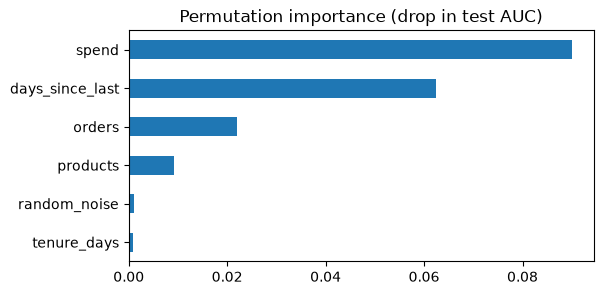

tenure_days        0.001
random_noise       0.001
products           0.009
orders             0.022
days_since_last    0.062
spend              0.090
dtype: float64

In [4]:
from sklearn.inspection import permutation_importance
perm = permutation_importance(rf, X_te_noise, y_test, scoring="roc_auc", n_repeats=10, random_state=42)
perm_s = pd.Series(perm.importances_mean, index=X_te_noise.columns).sort_values()
perm_s.plot.barh(figsize=(6, 3), title="Permutation importance (drop in test AUC)")
plt.show(); perm_s.round(3)

Now the random column is at about zero, where it belongs. (Values can even come out slightly negative: that just means shuffling happened to help by luck.) Permutation importance answers the question you actually care about: *how much worse is the model, on new customers, without this information?*

The tuned LightGBM (no noise column):

In [5]:
perm_lgb = permutation_importance(model, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=42)
pd.DataFrame({"mean drop in AUC": perm_lgb.importances_mean,
              "std": perm_lgb.importances_std}, index=features).sort_values("mean drop in AUC", ascending=False).round(3)

,mean drop in AUC,std
orders,0.054,0.005
spend,0.026,0.004
days_since_last,0.018,0.009
products,0.011,0.002
tenure_days,0.000,0.000


## 4. Partial dependence: which direction?

Importance says *how much* a feature matters, not *which way*. A **partial dependence plot** sets a feature to each value in turn for every customer, and averages the predicted churn probability.

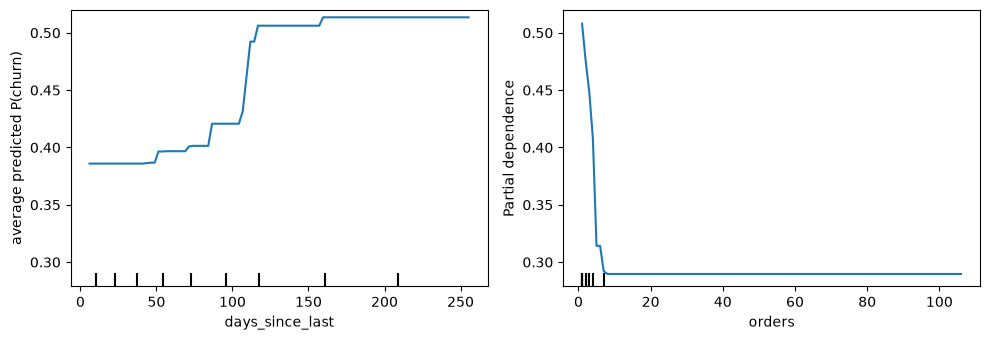

In [6]:
from sklearn.inspection import PartialDependenceDisplay
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
X_float = X_test.astype(float)                   # PDP needs float columns
PartialDependenceDisplay.from_estimator(model, X_float, ["days_since_last", "orders"], ax=axes)
axes[0].set_ylabel("average predicted P(churn)")
plt.tight_layout(); plt.show()

Two clear shapes:

- **days_since_last**: flat at about 39–40% for the first three months, then a jump between roughly 100 and 130 days to about 51%, then flat again. The model has learned a "silent for a whole season" threshold.
- **orders**: from about 51% for one-order customers down to about 31% at five orders, then flat. The difference between 1 and 5 orders matters; between 10 and 15 it does not.

Both match business intuition, which is reassuring. A shape that contradicts business sense is a red flag for a data problem.

## 5. Shapley values by hand

SHAP comes from a fair-credit idea in game theory. Players (features) join a team in some order; each gets credit for what the team's score gains when they join; average over all orders.

The README's toy churn-risk model, with two yes/no facts about a customer:

| known facts | predicted risk |
|---|---|
| none (average customer) | 10% |
| A = "no order in 60 days" | 30% |
| B = "only one order ever" | 20% |
| A and B | 50% |

In [7]:
from itertools import permutations
from math import factorial

def shapley(value, players):
    """Average each player's marginal contribution over every joining order."""
    credit = {p: 0.0 for p in players}
    for order in permutations(players):
        joined = frozenset()
        for p in order:
            credit[p] += value[joined | {p}] - value[joined]
            joined = joined | {p}
    return {p: c / factorial(len(players)) for p, c in credit.items()}

risk = {frozenset(): 10, frozenset("A"): 30, frozenset("B"): 20, frozenset("AB"): 50}
phi = shapley(risk, ["A", "B"])
print(phi)
print("base + contributions =", 10 + sum(phi.values()), " (prediction for A and B = 50)")

{'A': 25.0, 'B': 15.0}
base + contributions = 50.0  (prediction for A and B = 50)


A gets 25 points, B gets 15, and together with the 10% base they add up exactly to the 50% prediction. That **additivity** is what makes SHAP explanations easy to read: base value + one push per feature = the prediction.

## 6. SHAP on the real model

For tree models `shap.TreeExplainer` computes exact Shapley values quickly. LightGBM's values are in **log-odds** (the number before the sigmoid, see 03.4); positive pushes toward churn, negative toward staying.

In [8]:
import shap
explainer = shap.TreeExplainer(model)
sv = explainer(X_test)                            # one SHAP value per customer per feature
print("shape:", sv.values.shape)

raw = model.predict(X_test, raw_score=True)       # the model's log-odds output
print("additivity holds:", np.allclose(sv.base_values + sv.values.sum(axis=1), raw))

shape: (830, 5)
additivity holds: True


### Global view: the beeswarm

Each dot is one test customer. Position = how much that feature pushed their churn risk; colour = the feature's value (red high, blue low).

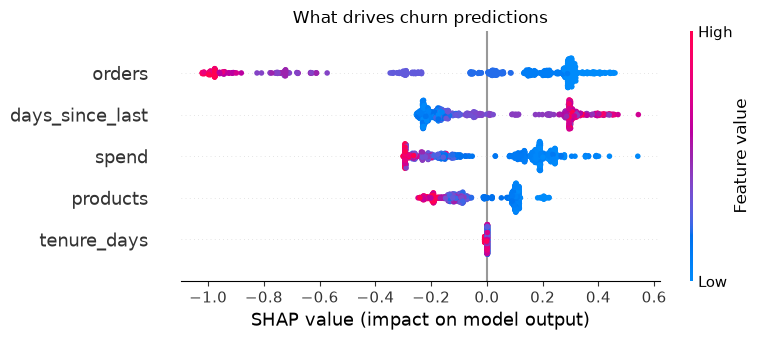

In [9]:
shap.plots.beeswarm(sv, show=False)
plt.title("What drives churn predictions"); plt.tight_layout(); plt.show()

In [10]:
mean_abs = pd.Series(np.abs(sv.values).mean(axis=0), index=features).sort_values(ascending=False)
mean_abs.round(3)

orders             0.363
days_since_last    0.219
spend              0.201
products           0.119
tenure_days        0.002
dtype: float64

Read the beeswarm row by row: for `orders`, red dots (many orders) sit on the left (lower churn risk) and blue dots (few orders) on the right. `orders` is the strongest driver overall (mean |SHAP| 0.36), followed by `days_since_last` and `spend` (about 0.2 each). `days_since_last` runs the other way: long gaps push right. `tenure_days` barely moves anyone: once you know how often and how recently someone buys, how long ago they first bought adds almost nothing.

### Local view: one customer

Pick the test customer with the highest predicted churn risk, and explain it.

In [11]:
proba = model.predict_proba(X_test)[:, 1]
i = int(proba.argmax())
print("customer:", X_test.index[i], f" predicted P(churn) = {proba[i]:.2f}")
X_test.iloc[i]

customer: 13747.0  predicted P(churn) = 0.66


orders               1.0
spend               79.6
products             1.0
tenure_days        273.0
days_since_last    273.0
Name: 13747.0, dtype: float64

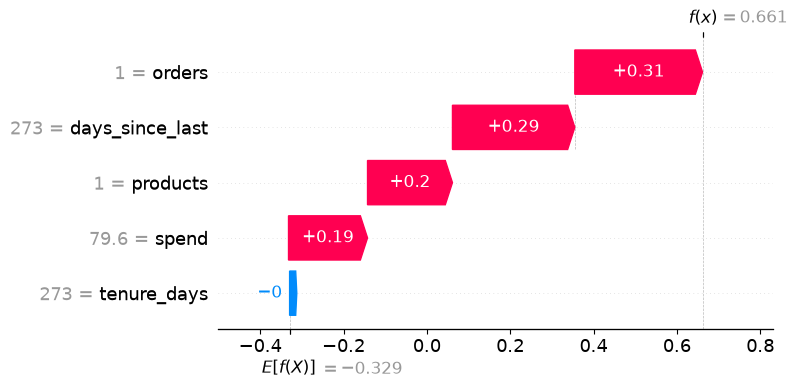

In [12]:
shap.plots.waterfall(sv[i], show=False)
plt.tight_layout(); plt.show()

The waterfall starts at the base value (the average log-odds), and each bar pushes this customer up or down until it reaches their prediction. Log-odds are not CEO language, so translate:

In [13]:
sigmoid = lambda z: 1 / (1 + np.exp(-z))
base_p = sigmoid(sv.base_values[i])
contrib = pd.Series(sv.values[i], index=features).sort_values(key=abs, ascending=False)
print(f"An average customer has a {base_p:.0%} chance of churning. This one: {proba[i]:.0%}.")
print("Main reasons:")
for f in contrib.index[:3]:
    direction = "raises" if contrib[f] > 0 else "lowers"
    print(f"  - {f} = {X_test.iloc[i][f]:,.0f} {direction} the risk")

An average customer has a 42% chance of churning. This one: 66%.
Main reasons:
  - orders = 1 raises the risk
  - days_since_last = 273 raises the risk
  - products = 1 raises the risk


That is an explanation a retention manager can act on: this customer bought once, a long time ago, for very little.

## 7. Which explanation when?

| Question | Tool |
|---|---|
| Which features does the model rely on overall? | Permutation importance (or mean \|SHAP\|) |
| In which direction does a feature push, on average? | Partial dependence, SHAP beeswarm |
| Why did the model score *this* customer like that? | SHAP waterfall |
| Quick look during development | Built-in importance (but remember its bias) |

None of these says *why customers churn* in the real world. They say why the **model** predicts what it predicts. Cause and effect needs experiments (for example, randomly sending vouchers and measuring the difference).

## Quiz answers

1. Global explains the model's behaviour over all customers (which features matter overall); local explains one prediction (why this customer got this score).
2. It favours features with many distinct values (continuous or ID-like), which offer many split points, and it is computed on training data, so it rewards memorisation. The random column proved it.
3. Shuffle one feature's column in the test data, re-score the model, and measure the drop. Large drop = important.
4. Orders A→B: A gets 30−10 = 20, B gets 50−30 = 20. Order B→A: B gets 20−10 = 10, A gets 50−20 = 30. Average: A = 25, B = 15. Sum 40 = 50 − 10.
5. base value + sum of SHAP values = the model's output for that customer (in log-odds for LightGBM).

**Next:** [05.9 AutoML in industry](../09-automl-pycaret/) (optional) or [05.10 Choosing and saving the final model](../10-choosing-and-saving/)